# 04 · Hallucinations: do the curves notice them?

Proof of concept on the texts notebook 03 made. Two questions, both on raw curves:

1. **Text level.** The 2 clusters of the 25 real texts (GloVe top 5) stay fixed (`docs/adr/0003`). Each new text
   goes to the cluster whose centre text's curve is nearest (DTW). Does a hallucinated text land where its kind does?
2. **Word level.** Does the curve react *at* a hallucination (or a few words after)?
   - **planted texts**: the curve is lined up with the clean original's (DTW) and the gap at every word is shown;
     for each planted word: its gap, the rank of that gap in the whole text, and where the largest gap falls
     within the next few words. In real use there is no clean original, so the planted word's rank in the text's
     **own curve** (1 = the highest value in the text) is the realistic test
   - **switch stories**: the curve next to the 0.7 story it continues, with the switch point marked
   - **generated stories**: hallucinations found by reading, and where each one ranks in the text's own curve
3. **Unusual stretches (matrix profile).** Without any clean original: every stretch of 3 measured words is compared
   with every other stretch of the same text (raw values, `stumpy.aamp`); a stretch unlike anything else in the text
   is an anomaly. The 3 most unusual stretches are shaded yellow. Does a hallucination fall inside one?

Word-level signals: **surprisal per word, names included** (nouns, verbs and names such as Hermione or London, read
from the token table) and GloVe distance top 1 vs real word (nouns and verbs only: names have no GloVe guesses).
Reads what notebook 03 saved (no model run). Results go to `results/hallucinated/`.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore")
# make this folder's qwen_config.py and analysis/ importable, wherever Jupyter was started (e.g. the repo root)
QWEN7B_DIR = Path.cwd()
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src/note_books/Qwen7B/qwen_config.py").exists():
        QWEN7B_DIR = folder / "src/note_books/Qwen7B"
        break
sys.path.insert(0, str(QWEN7B_DIR))

import analysis                                # also makes lca_core (repo root) importable
import matplotlib.pyplot as plt
import pandas as pd

from analysis.cluster import cluster, in_right_cluster
from analysis.figures import plot_word_curves, save_to
from analysis.hallucinations import (anomaly_profile, curve_position, first_row_from_char, generated_texts,
                                     in_top_anomalies, marked_hallucinations, place, planted_texts, rank_in_curve,
                                     reaction, row_at_char, stretch_rank, switch_points, top_anomalies, word_gaps,
                                     write_review)
from analysis.signals import (curve_with_rows, curves_of, dataset_names, kinds_of, load_tables, signal_by_key,
                              words_with_names)
from qwen_config import (ANOMALIES_SHOWN, ANOMALY_WINDOW, HALLUCINATED_DIR, HALLUCINATED_FIGURES_DIR,
                         HALLUCINATED_TABLES_DIR, HALLUCINATED_TOKENS_DIR, HALLUCINATED_WORDS_DIR, MODEL_NAME,
                         PLACEMENT_SIGNAL, REACTION_WORDS, SECOND_READER_MODEL, SECOND_READER_TOKENS_DIR, TEXTS_DIR,
                         WORD_LEVEL_SIGNALS)

real_names = dataset_names()
real_kinds = kinds_of(real_names)
real_words, real_tokens = load_tables(real_names, MODEL_NAME)

new_names = []
for path in sorted(HALLUCINATED_WORDS_DIR.glob("*.csv")):
    new_names.append(path.stem)
new_words, new_tokens = load_tables(new_names, MODEL_NAME, HALLUCINATED_WORDS_DIR, HALLUCINATED_TOKENS_DIR)
planted = planted_texts()
switches = switch_points()
marks = marked_hallucinations()
HALLUCINATED_TABLES_DIR.mkdir(parents=True, exist_ok=True)
write_review(HALLUCINATED_DIR / "REVIEW.md")


# nouns, verbs AND names of every text, with the confidence values at each (from the token tables)
texts = {}
for name in real_names:
    texts[name] = (TEXTS_DIR / f"{name}.txt").read_text(encoding="utf-8")
for name, (_original, text, _edits) in planted.items():
    texts[name] = text
texts.update(generated_texts())
named_words = {}
for name in real_names:
    named_words[name] = words_with_names(texts[name], real_tokens[name])
for name in new_names:
    named_words[name] = words_with_names(texts[name], new_tokens[name])


def word_curve(signal_key, name):
    # (signal name, values, table rows, table) of one text's word-level curve. Surprisal per word is read from the
    # names-included table; the guess-meaning signals from the word table (nouns and verbs only).
    if signal_key == "surprisal_per_word":
        table = named_words[name]
        values, rows = curve_with_rows(table, "surprisal")
        return "surprisal per word (names included)", values, rows, table
    signal = signal_by_key(signal_key)
    if name in real_words:
        table = real_words[name]
    else:
        table = new_words[name]
    values, rows = curve_with_rows(table, signal.column)
    return signal.name, values, rows, table


def profile_panel(signal_name, values):
    # (matrix-profile panel, its profile, its most unusual stretches) for one curve
    profile = anomaly_profile(values, ANOMALY_WINDOW)
    stretches = top_anomalies(profile, ANOMALY_WINDOW, ANOMALIES_SHOWN)
    panel = {"signal": f"how unusual ({ANOMALY_WINDOW}-word stretches)",
             "curve": profile, "stretches": stretches, "window": ANOMALY_WINDOW}
    return panel, profile, stretches


def group_of(name):
    if "_planted" in name:
        return "planted"
    return {"t07": "temperature 0.7", "t10": "temperature 1.0", "switch": "switch 0.7 → 1.0"}[name.rsplit("_", 1)[1]]


print(f"{len(real_names)} real texts, {len(new_names)} new texts")

25 real texts, 17 new texts


## 1. Text level: which fixed cluster does each new text land in?

In [2]:
placement_signal = signal_by_key(PLACEMENT_SIGNAL)
real_curves = curves_of(placement_signal, real_names, real_words, real_tokens)
labels, centres, _distances = cluster(real_curves)
correct = in_right_cluster(real_kinds, labels)
cluster_kind = {}
for cluster_label in [0, 1]:
    members = labels == cluster_label
    cluster_kind[cluster_label] = pd.Series(real_kinds[members]).mode()[0]
centre_curves = [real_curves[centres[0]], real_curves[centres[1]]]
print(f"{placement_signal.name}: centres {real_names[centres[0]]} ({cluster_kind[0]} cluster), "
      f"{real_names[centres[1]]} ({cluster_kind[1]} cluster); {correct.sum()}/{len(real_names)} real texts right")

placement_rows = []
new_curves = curves_of(placement_signal, new_names, new_words, new_tokens)
for name, values in zip(new_names, new_curves):
    nearest, distances = place(values, centre_curves, real_curves)
    row = {"text": name, "kind": kinds_of([name])[0], "made as": group_of(name),
           "lands in": f"{cluster_kind[nearest]} cluster",
           f"DTW to {cluster_kind[0]} centre": round(distances[0], 2),
           f"DTW to {cluster_kind[1]} centre": round(distances[1], 2)}
    if name in planted:
        original_index = real_names.index(planted[name][0])
        row["clean original lands in"] = f"{cluster_kind[labels[original_index]]} cluster"
    placement_rows.append(row)
placement = pd.DataFrame(placement_rows)
placement.to_csv(HALLUCINATED_TABLES_DIR / "placement.csv", index=False)
placement

GloVe distance, top 5 guesses: centres factual_gut_candle (creative cluster), factual_gut_outline_science (factual cluster); 23/25 real texts right


,text,kind,made as,lands in,DTW to creative centre,DTW to factual centre,clean original lands in
0,creative_gen_detective_switch,creative,switch 0.7 → 1.0,creative cluster,1.24,1.29,NaN
1,creative_gen_detective_t07,creative,temperature 0.7,creative cluster,1.27,1.29,NaN
2,creative_gen_detective_t10,creative,temperature 1.0,factual cluster,0.97,0.95,NaN
3,creative_gen_fairy_switch,creative,switch 0.7 → 1.0,factual cluster,1.08,1.02,NaN
4,creative_gen_fairy_t07,creative,temperature 0.7,factual cluster,1.01,0.97,NaN
5,creative_gen_fairy_t10,creative,temperature 1.0,creative cluster,1.13,1.23,NaN
6,creative_gen_magic_switch,creative,switch 0.7 → 1.0,creative cluster,1.12,1.21,NaN
7,creative_gen_magic_t07,creative,temperature 0.7,creative cluster,1.11,1.17,NaN
8,creative_gen_magic_t10,creative,temperature 1.0,creative cluster,1.08,1.19,NaN
9,creative_gut_grimm_planted,creative,planted,creative cluster,1.07,1.14,creative cluster


## 2. Word level: planted hallucinations
Red lines: the planted words. Panels: the planted text's raw curve (grey underneath: the clean original's) and the
gap to the clean original at every word; under the surprisal curve, its matrix profile with the 3 most unusual
stretches shaded yellow. A planted word the tagger did not take as a noun, verb or name, or that a signal has no
value for, is listed as *not on the curve*.

Columns: **rank in own curve** (1 = highest value in the text; no clean original needed), **in top 3 unusual
stretches** and **stretch rank** (matrix profile; no clean original needed), and the gap columns (need the original).

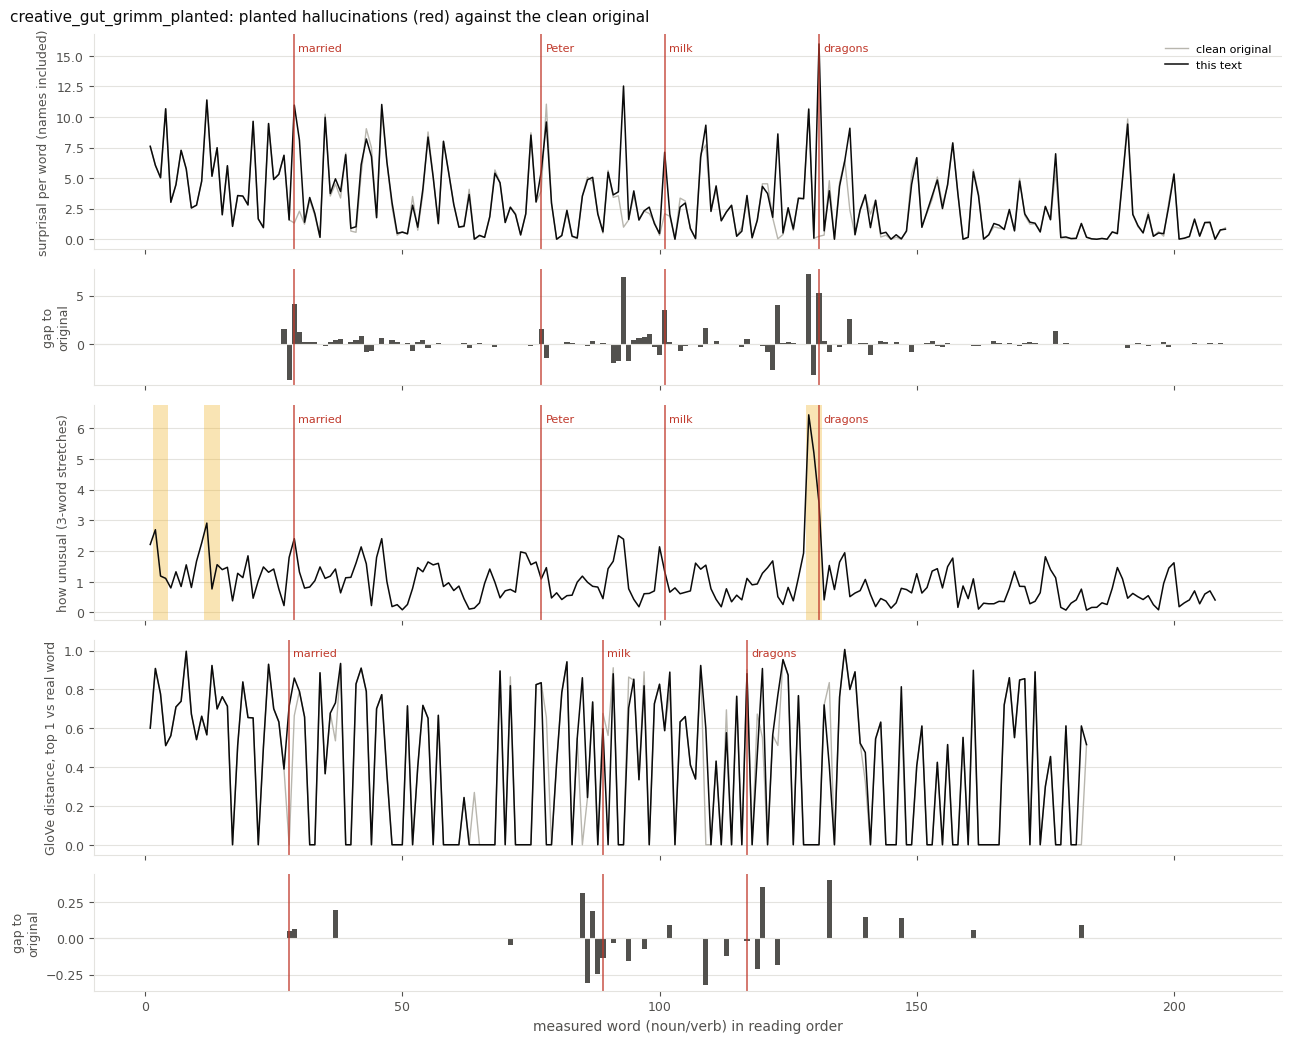

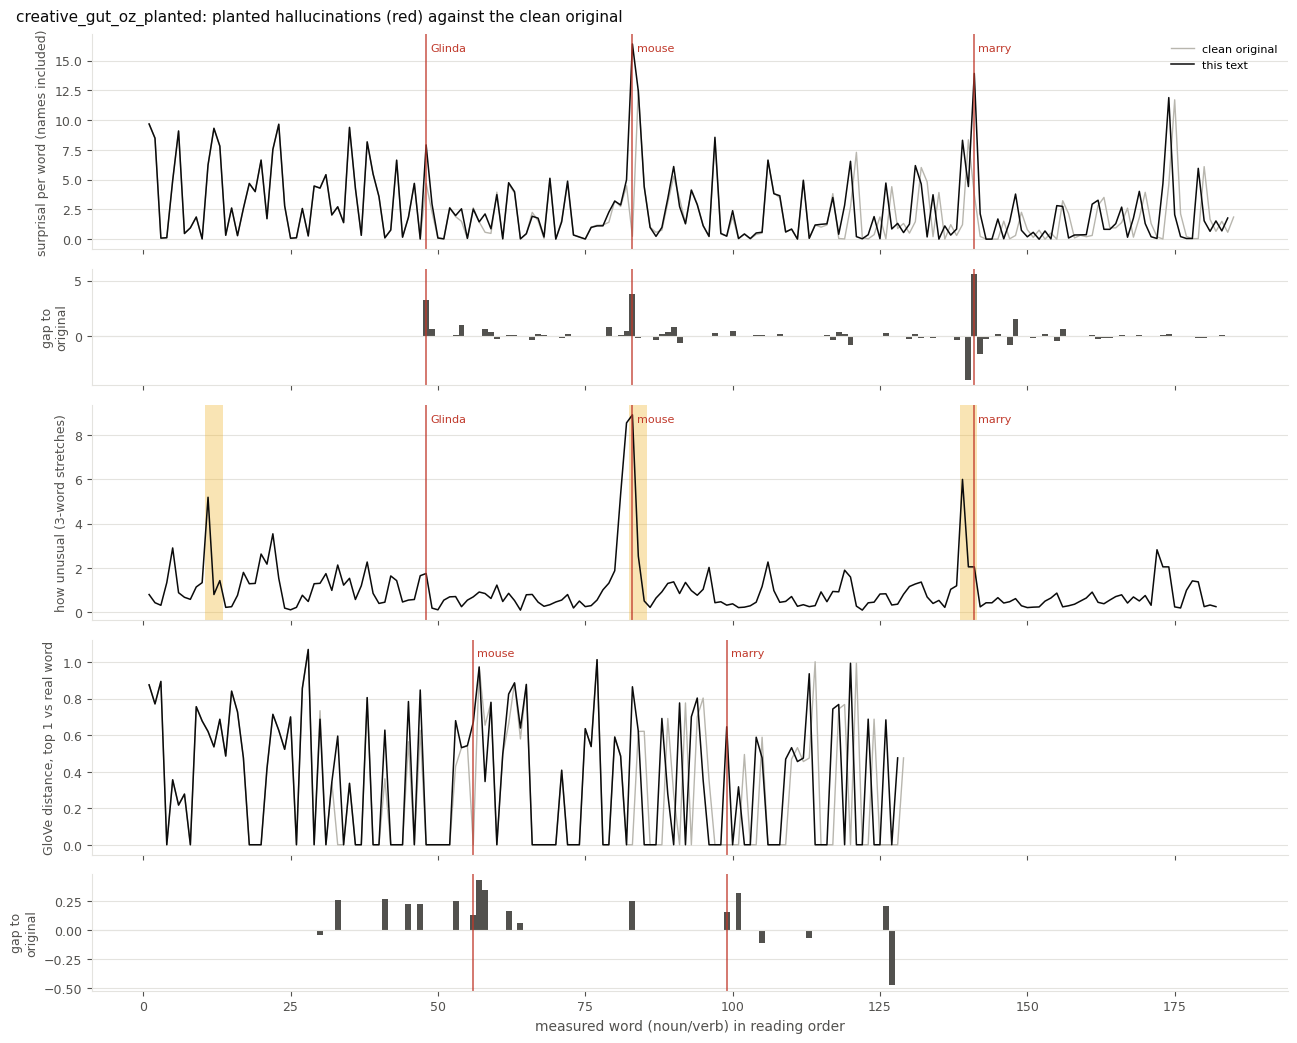

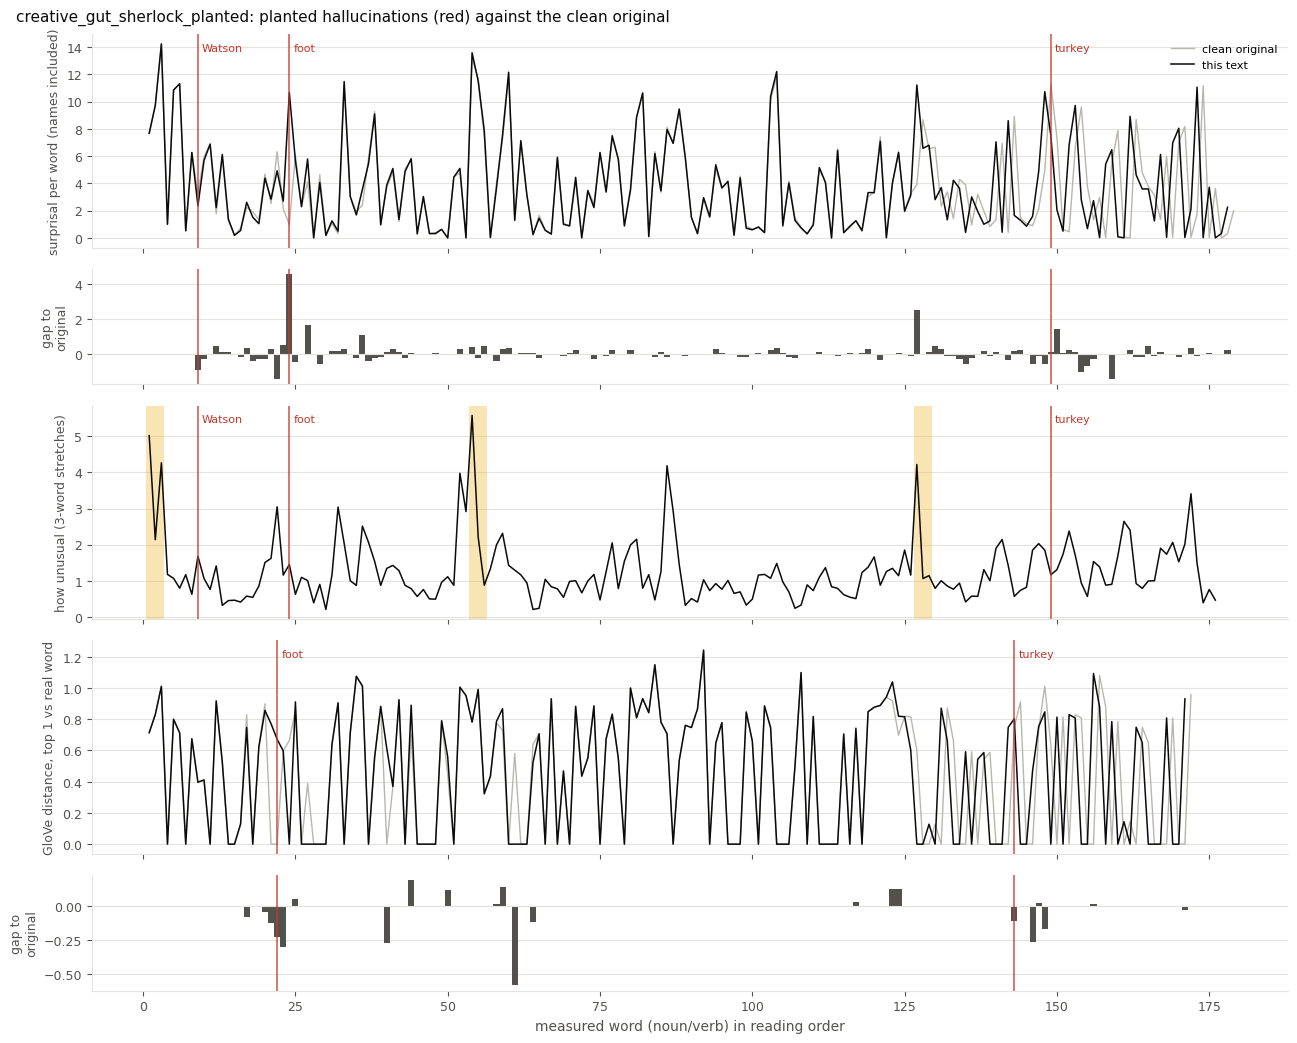

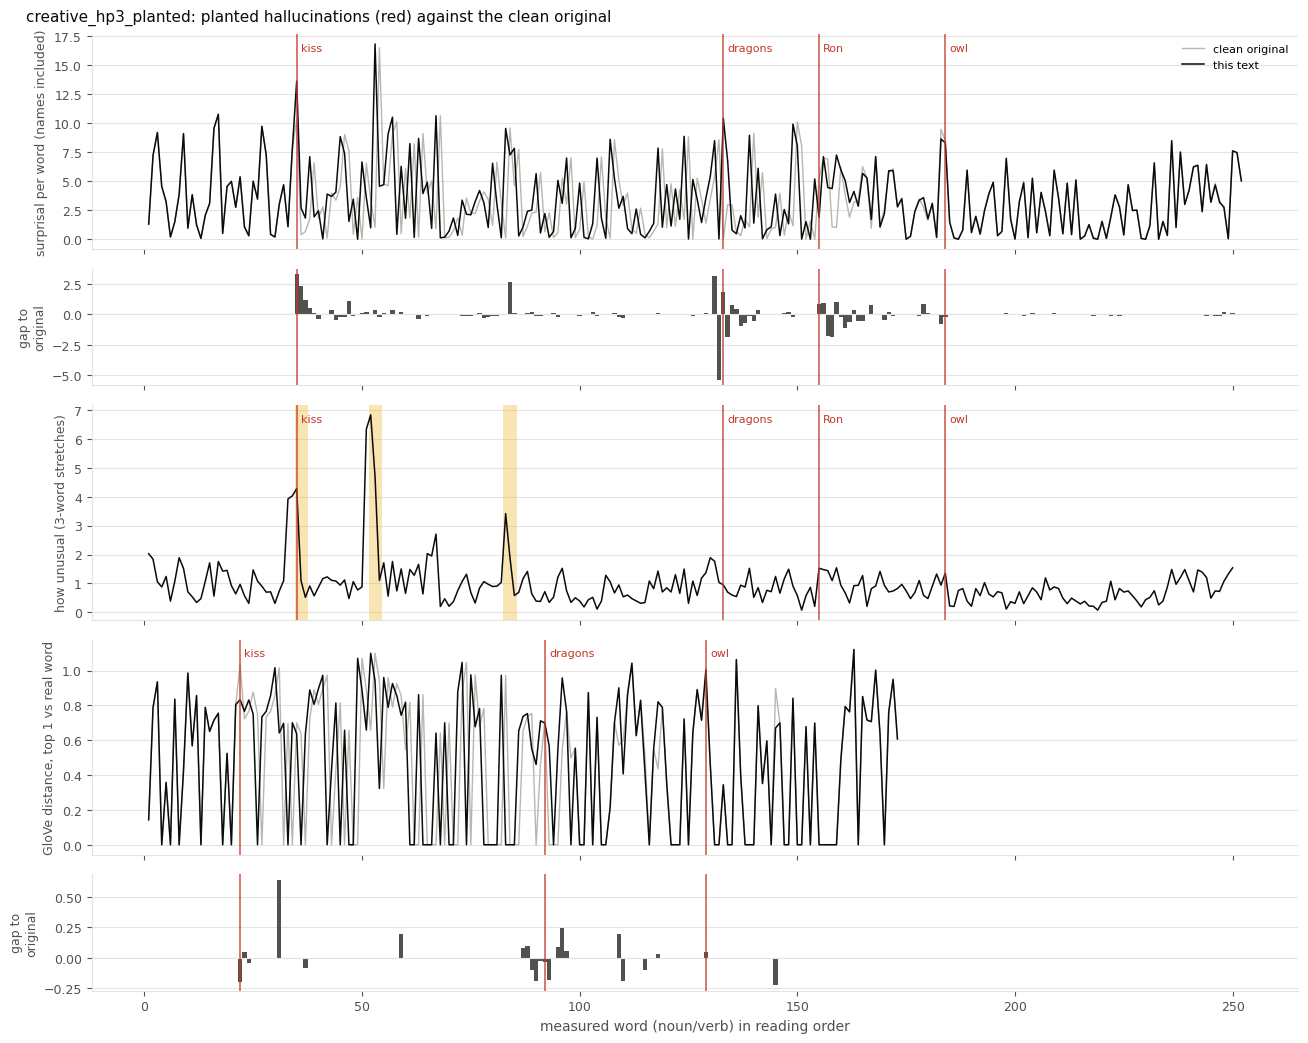

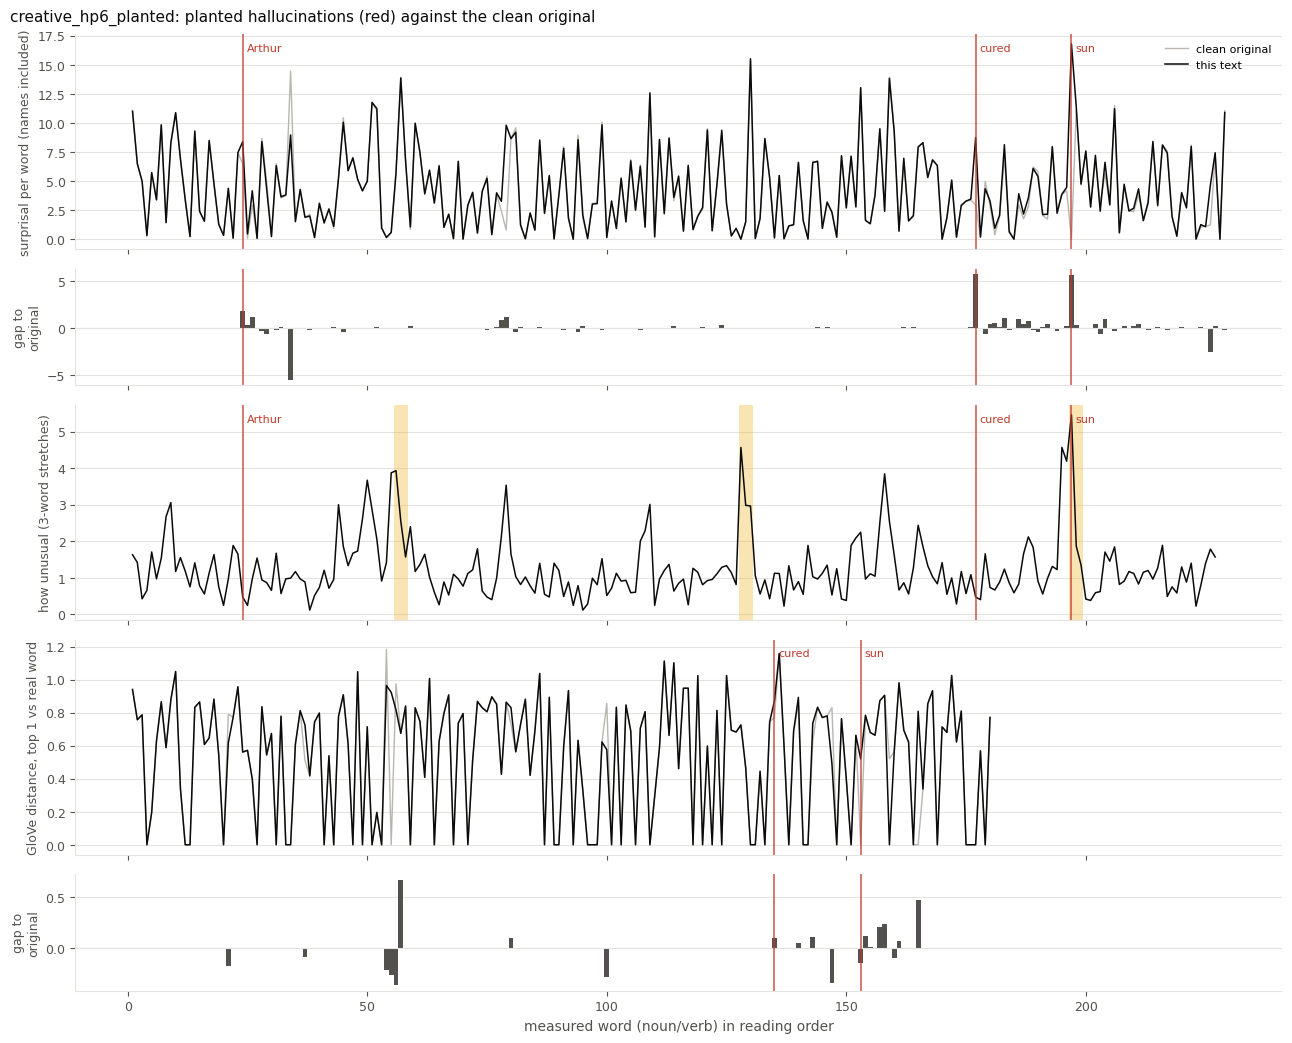

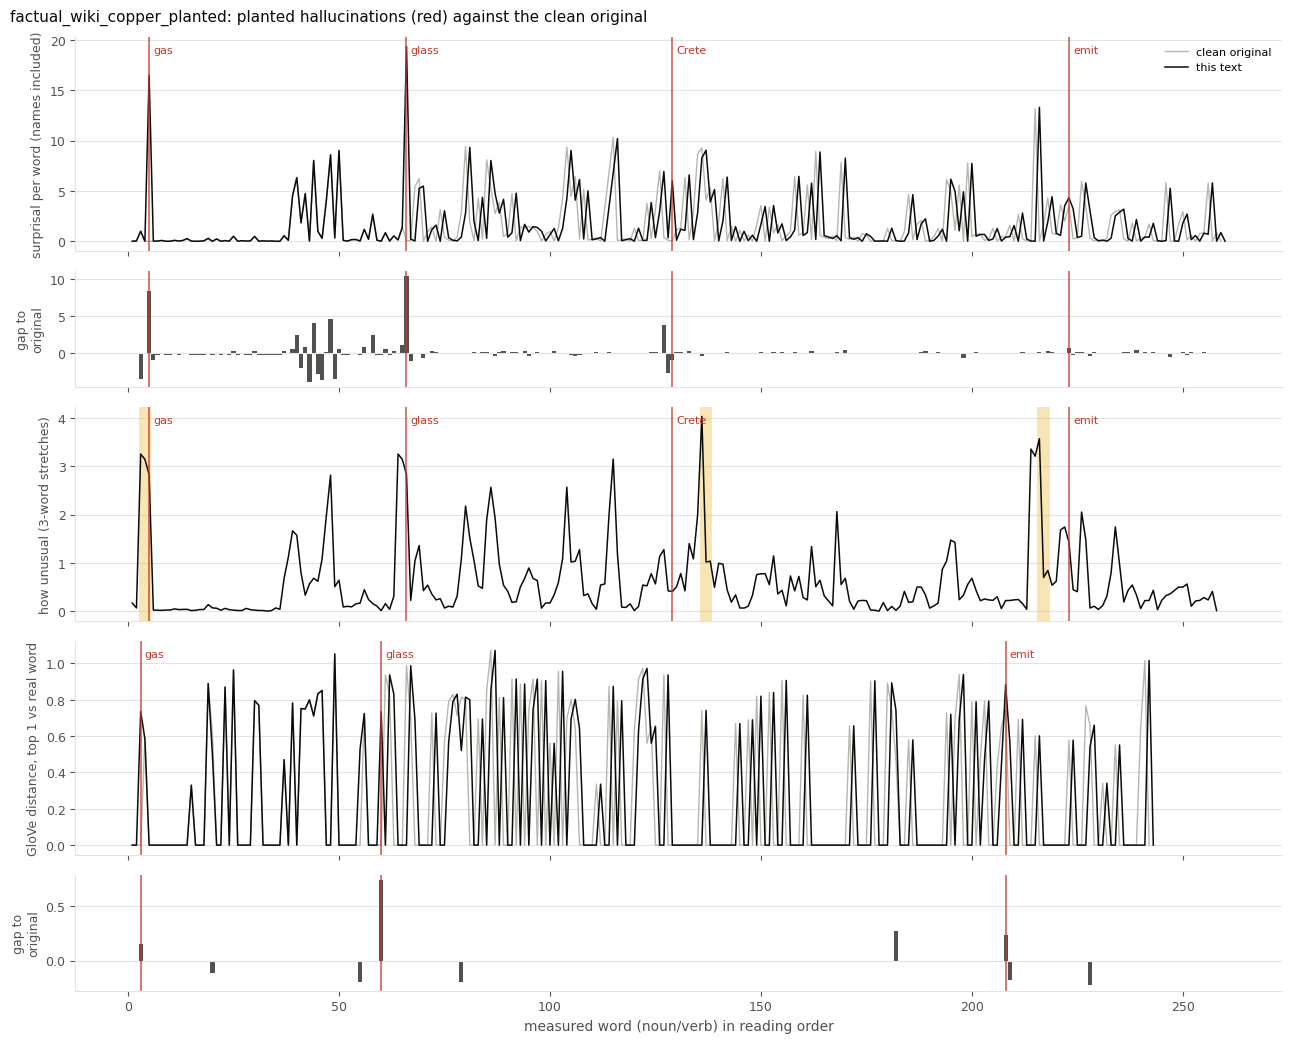

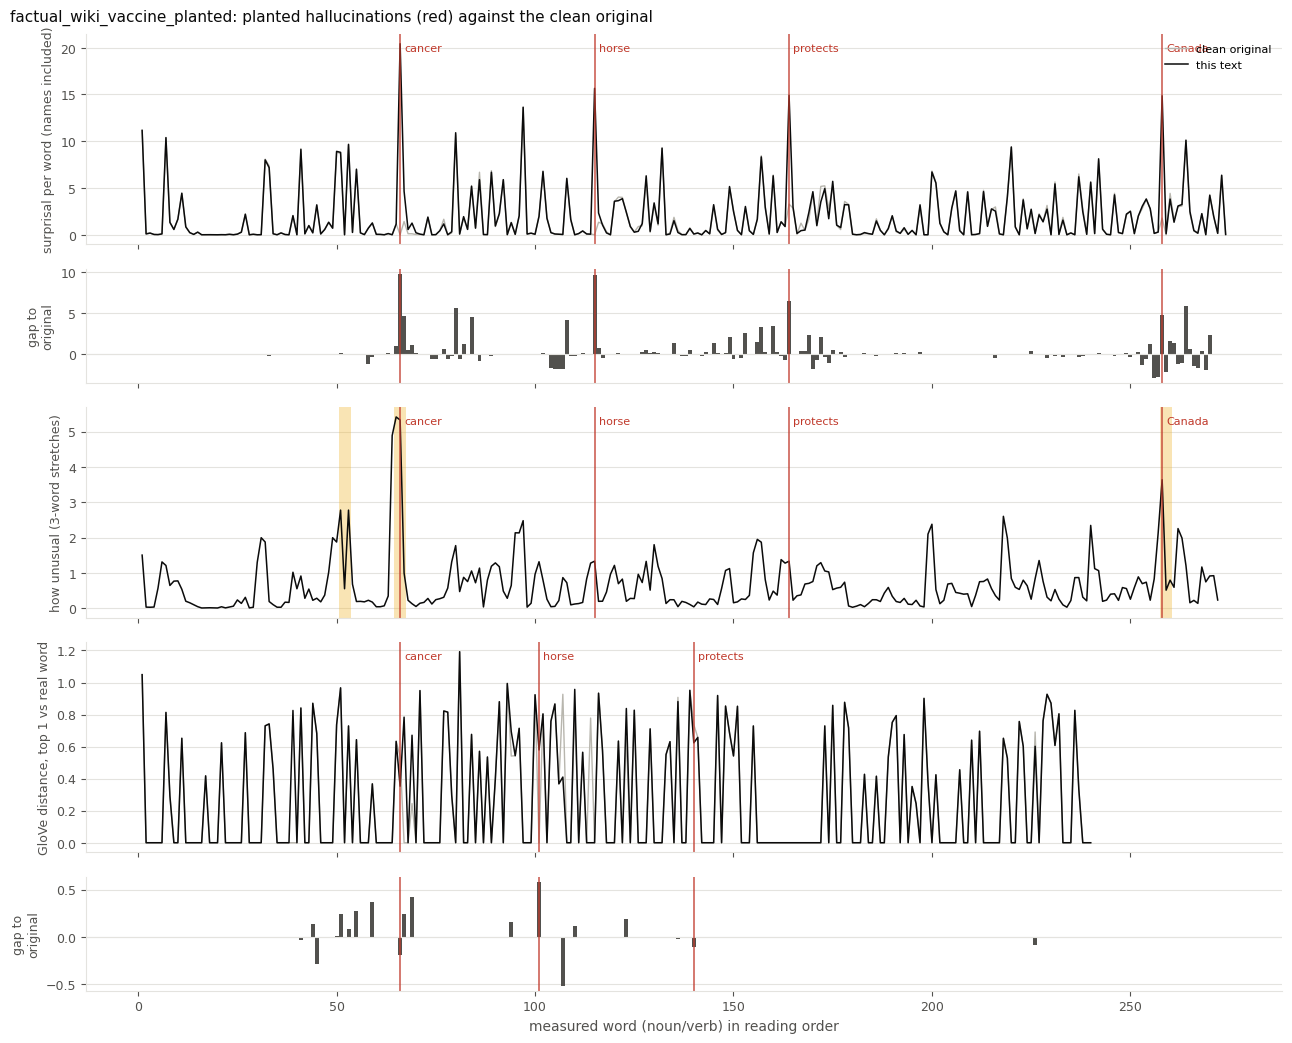

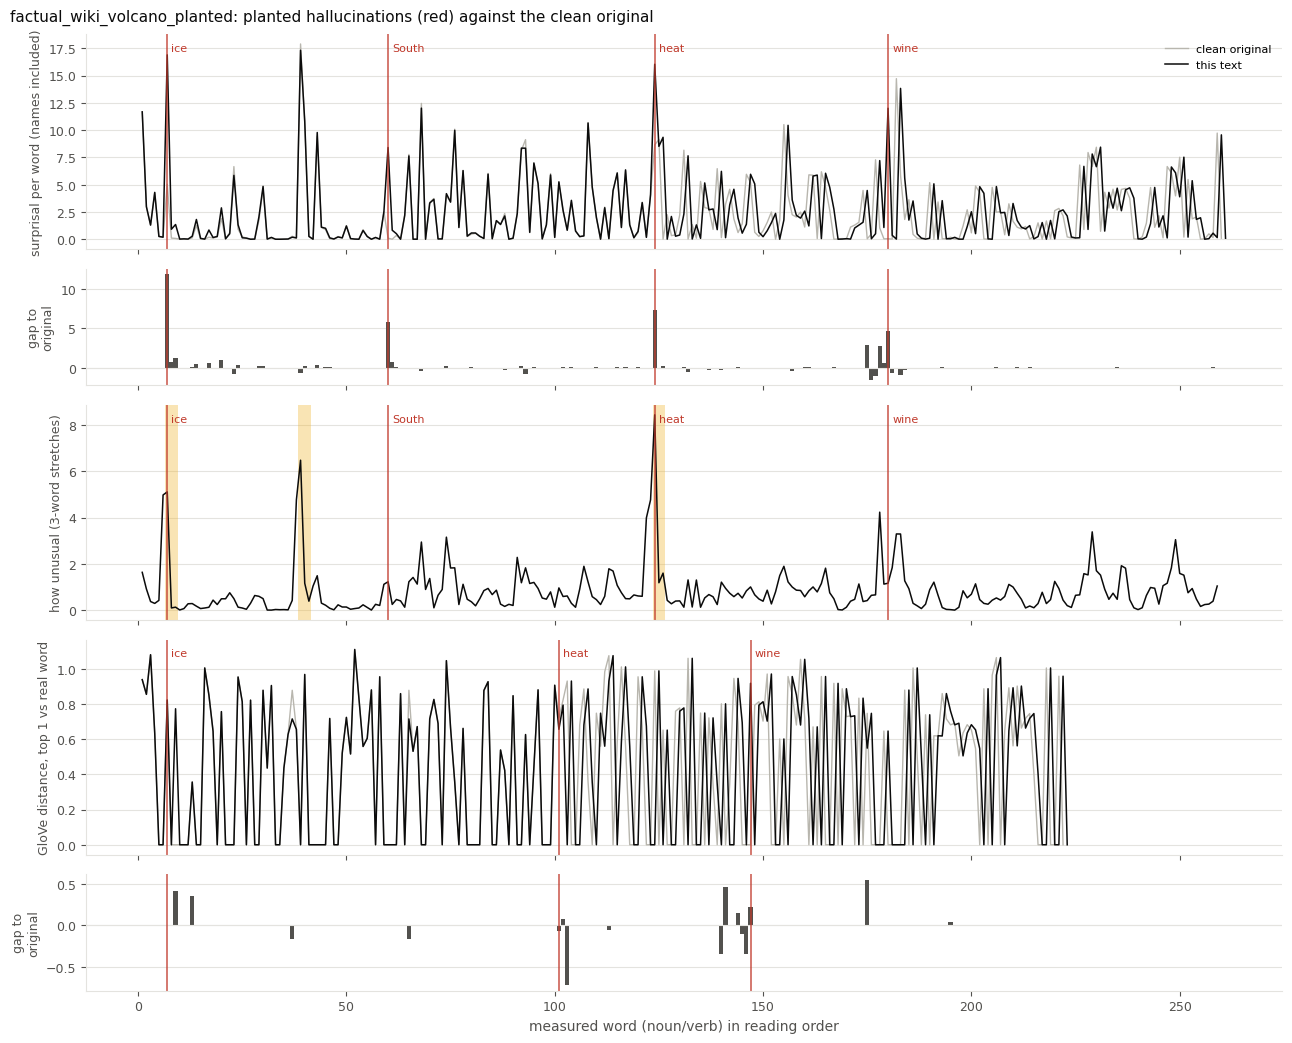

,text,planted,type,is a name,signal,rank in own curve,in top 3 unusual stretches,stretch rank,gap at word,rank of |gap| in text,largest |gap| at,largest |gap|,words on curve
0,creative_gut_grimm_planted,died → married,relation,False,surprisal per word (names included),5,False,7.0,4.105,4.0,+0 words,4.105,210.0
1,creative_gut_grimm_planted,Hans → Peter,entity,True,surprisal per word (names included),39,False,27.0,1.564,15.0,+0 words,1.564,210.0
2,creative_gut_grimm_planted,beer → milk,entity,False,surprisal per word (names included),25,False,12.0,3.516,7.0,+0 words,3.516,210.0
3,creative_gut_grimm_planted,masons → dragons,invented,False,surprisal per word (names included),1,True,1.0,5.277,3.0,+0 words,5.277,210.0
4,creative_gut_grimm_planted,died → married,relation,False,"GloVe distance, top 1 vs real word",54,NaN,NaN,0.049,21.0,+1 words,0.068,183.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,factual_wiki_volcano_planted,fire → wine,entity,False,surprisal per word (names included),6,False,7.0,4.725,4.0,+0 words,4.725,261.0
60,factual_wiki_volcano_planted,lava → ice,entity,False,"GloVe distance, top 1 vs real word",50,NaN,NaN,0.002,17.0,+2 words,0.416,223.0
61,factual_wiki_volcano_planted,North → South,entity,True,"GloVe distance, top 1 vs real word",not on the curve,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,factual_wiki_volcano_planted,cool → heat,relation,False,"GloVe distance, top 1 vs real word",91,NaN,NaN,-0.064,14.0,+2 words,0.720,223.0


In [3]:
reaction_rows = []
for name, (original_name, _text, edits) in planted.items():
    panels = []
    marks_by_signal = {}
    for signal_key in WORD_LEVEL_SIGNALS:
        signal_name, values, rows, table = word_curve(signal_key, name)
        _same, original_values, _original_rows, _original_table = word_curve(signal_key, original_name)
        gaps = word_gaps(values, original_values)
        panels.append({"signal": signal_name, "curve": values, "original": original_values, "gaps": gaps})
        profile = None
        if signal_key == "surprisal_per_word":
            panel, profile, stretches = profile_panel(signal_name, values)
            panels.append(panel)
        marks_by_signal[signal_name] = []
        for edit in edits:
            position = curve_position(rows, row_at_char(table, edit["char"]))
            row = {"text": name, "planted": f"{edit['original']} → {edit['planted']}", "type": edit["type"],
                   "is a name": edit["planted"][:1].isupper(), "signal": signal_name}
            if position is None:
                row["rank in own curve"] = "not on the curve"
            else:
                marks_by_signal[signal_name].append((position, edit["planted"]))
                row["rank in own curve"] = rank_in_curve(values, position)
                if profile is not None:
                    marks_by_signal.setdefault(panel["signal"], []).append((position, edit["planted"]))
                    row["in top 3 unusual stretches"] = in_top_anomalies(position, stretches, ANOMALY_WINDOW)
                    row["stretch rank"] = stretch_rank(profile, position, ANOMALY_WINDOW)
                row.update(reaction(gaps, position, REACTION_WORDS))
                row["words on curve"] = len(values)
            reaction_rows.append(row)
    figure = plot_word_curves(f"{name}: planted hallucinations (red) against the clean original", panels,
                              marks_by_signal)
    save_to(figure, HALLUCINATED_FIGURES_DIR, f"planted_{name}.png")
    plt.show()

reactions = pd.DataFrame(reaction_rows)
reactions.to_csv(HALLUCINATED_TABLES_DIR / "planted_reactions.csv", index=False)
reactions.round(3)

## 3. Word level: the temperature switch
Each switch story is identical to its 0.7 story up to the switch point (dashed line), then continues at 1.0.
Grey: the 0.7 story's curve. Before the switch the two curves are the same text, so their gap is 0. The table counts
how many of the 3 most unusual stretches (surprisal matrix profile) fall after the switch.

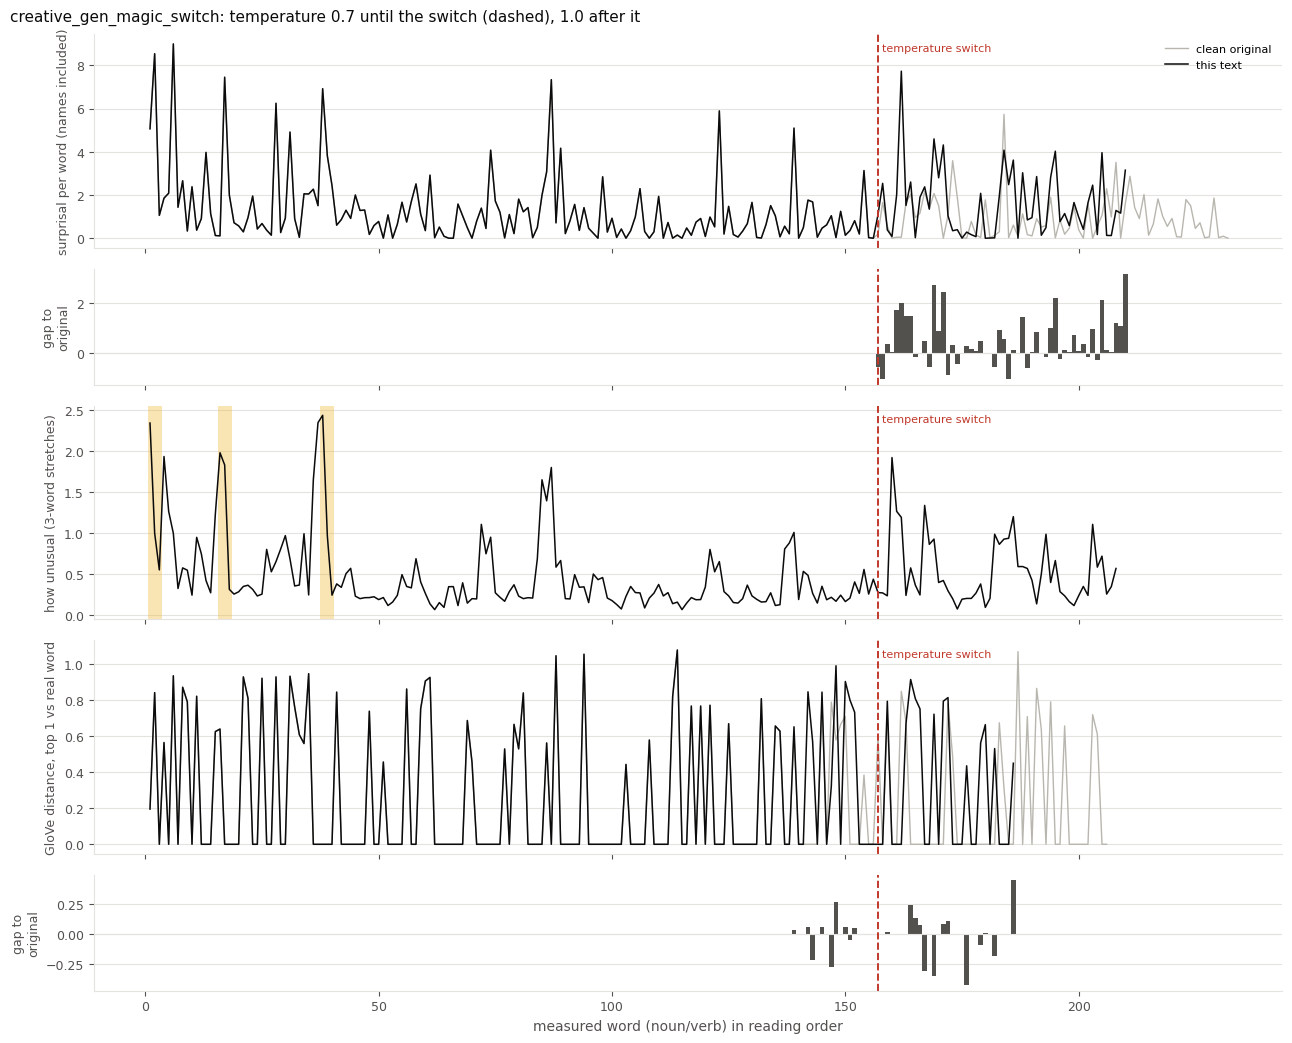

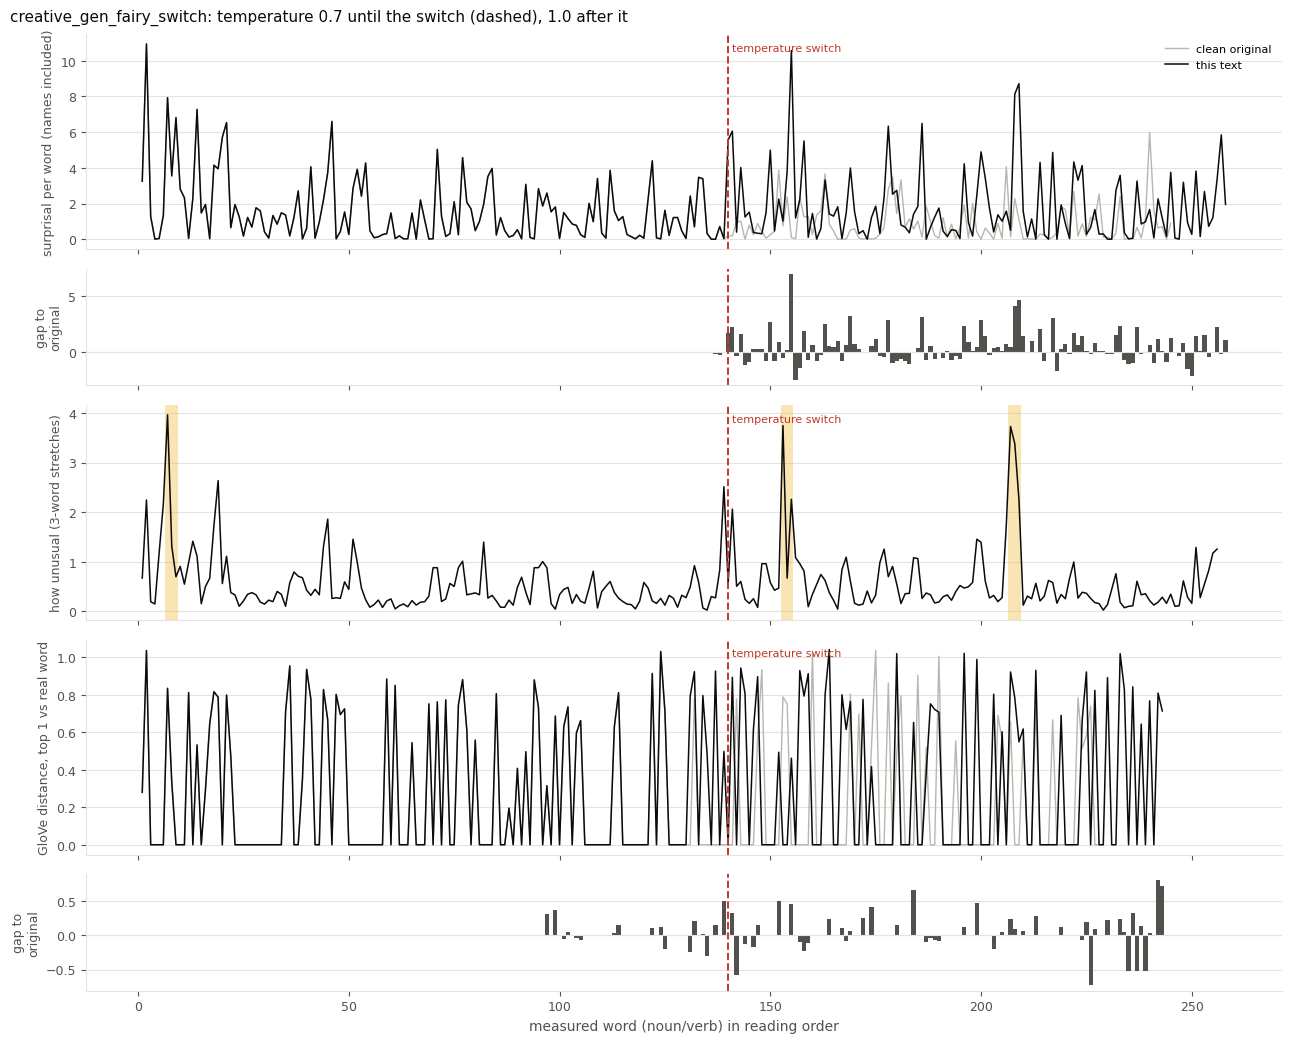

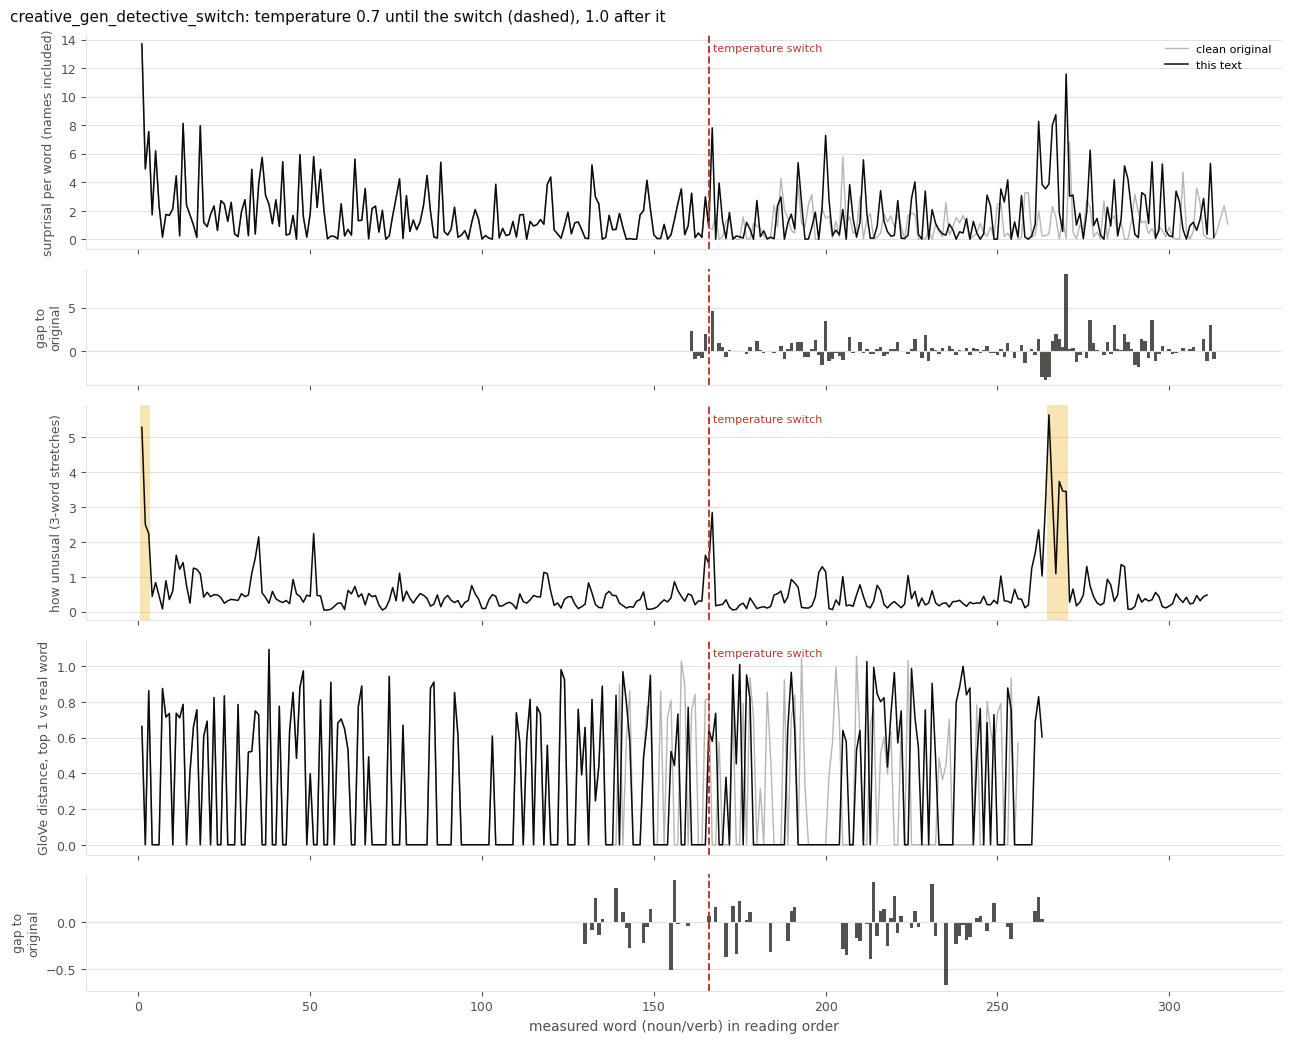

,text,words on curve,words before switch,unusual stretches after the switch
0,creative_gen_magic_switch,210,156,0 of 3
1,creative_gen_fairy_switch,258,139,2 of 3
2,creative_gen_detective_switch,313,165,2 of 3


In [4]:
switch_rows = []
for _index, switch in switches.iterrows():
    name, original_name = switch["text"], switch["clean original"]
    panels = []
    switch_position = None
    for signal_key in WORD_LEVEL_SIGNALS:
        signal_name, values, rows, table = word_curve(signal_key, name)
        _same, original_values, _original_rows, _original_table = word_curve(signal_key, original_name)
        panels.append({"signal": signal_name, "curve": values, "original": original_values,
                       "gaps": word_gaps(values, original_values)})
        if signal_key == "surprisal_per_word":
            switch_position = curve_position(rows, first_row_from_char(table, int(switch["switch char"])))
            panel, _profile, stretches = profile_panel(signal_name, values)
            panels.append(panel)
            after = 0
            for start in stretches:
                if start >= switch_position:
                    after += 1
            switch_rows.append({"text": name, "words on curve": len(values), "words before switch": switch_position,
                                "unusual stretches after the switch": f"{after} of {len(stretches)}"})
    figure = plot_word_curves(f"{name}: temperature 0.7 until the switch (dashed), 1.0 after it", panels, {},
                              switch_position)
    save_to(figure, HALLUCINATED_FIGURES_DIR, f"switch_{name}.png")
    plt.show()
pd.DataFrame(switch_rows)

## 4. Word level: hallucinations found by reading the generated stories
Marked in `generated/marks.csv` (reviewed by hand). For each one: where it ranks in its own text's curve
(1 = the highest value in the text) and whether it falls in one of the 3 most unusual stretches.

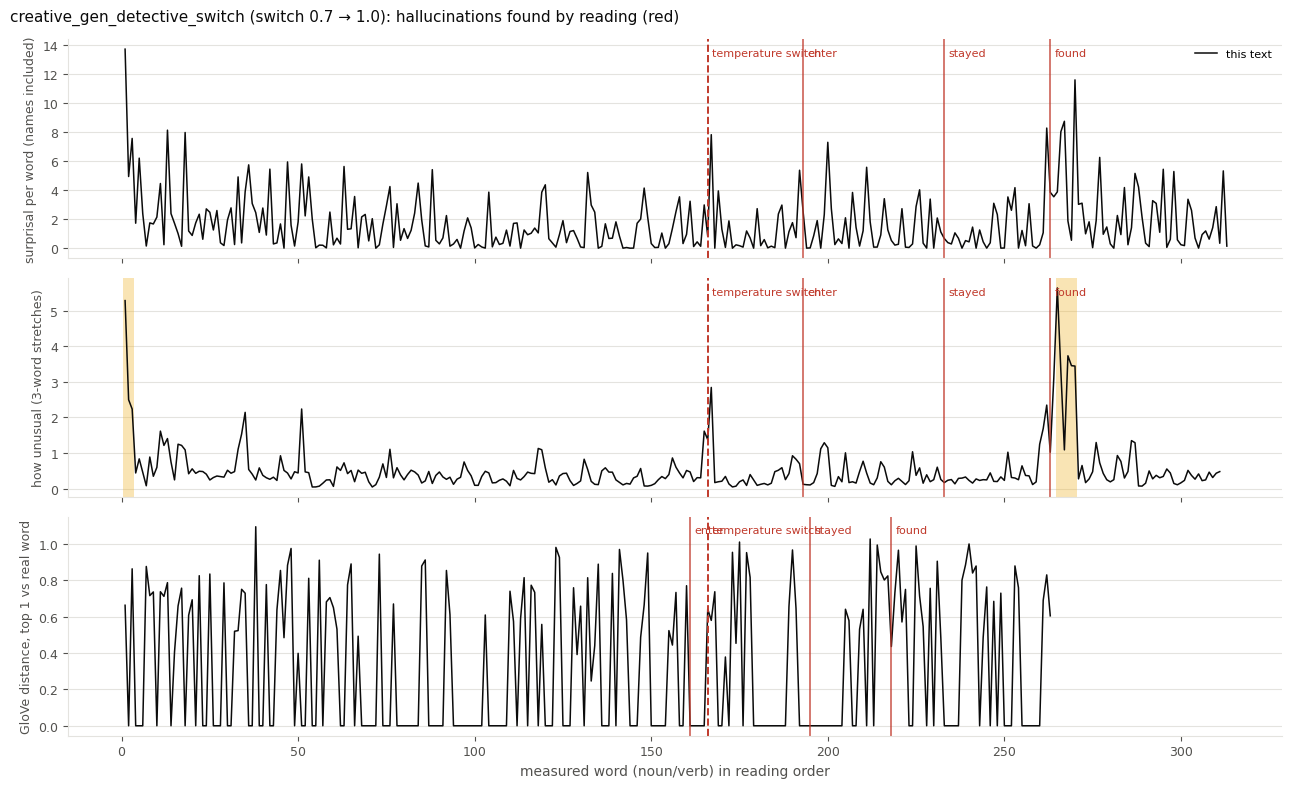

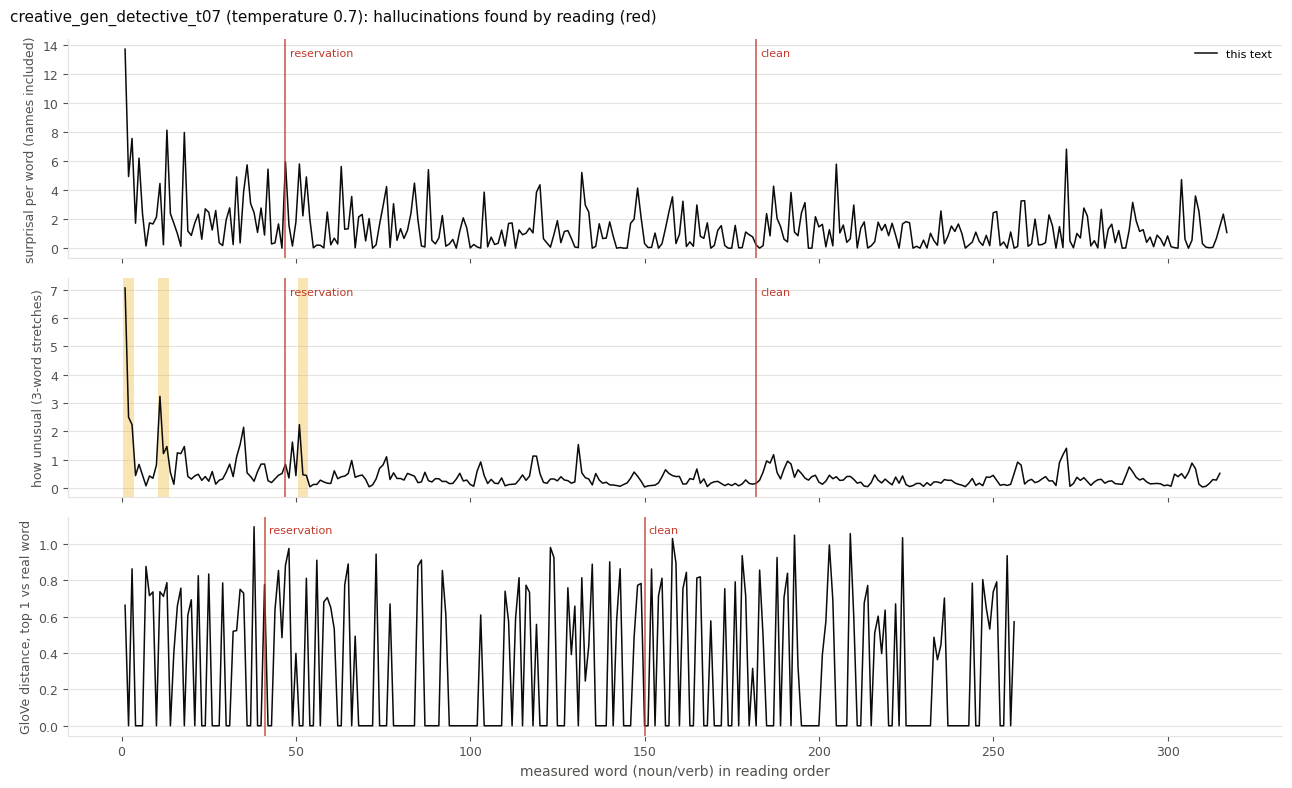

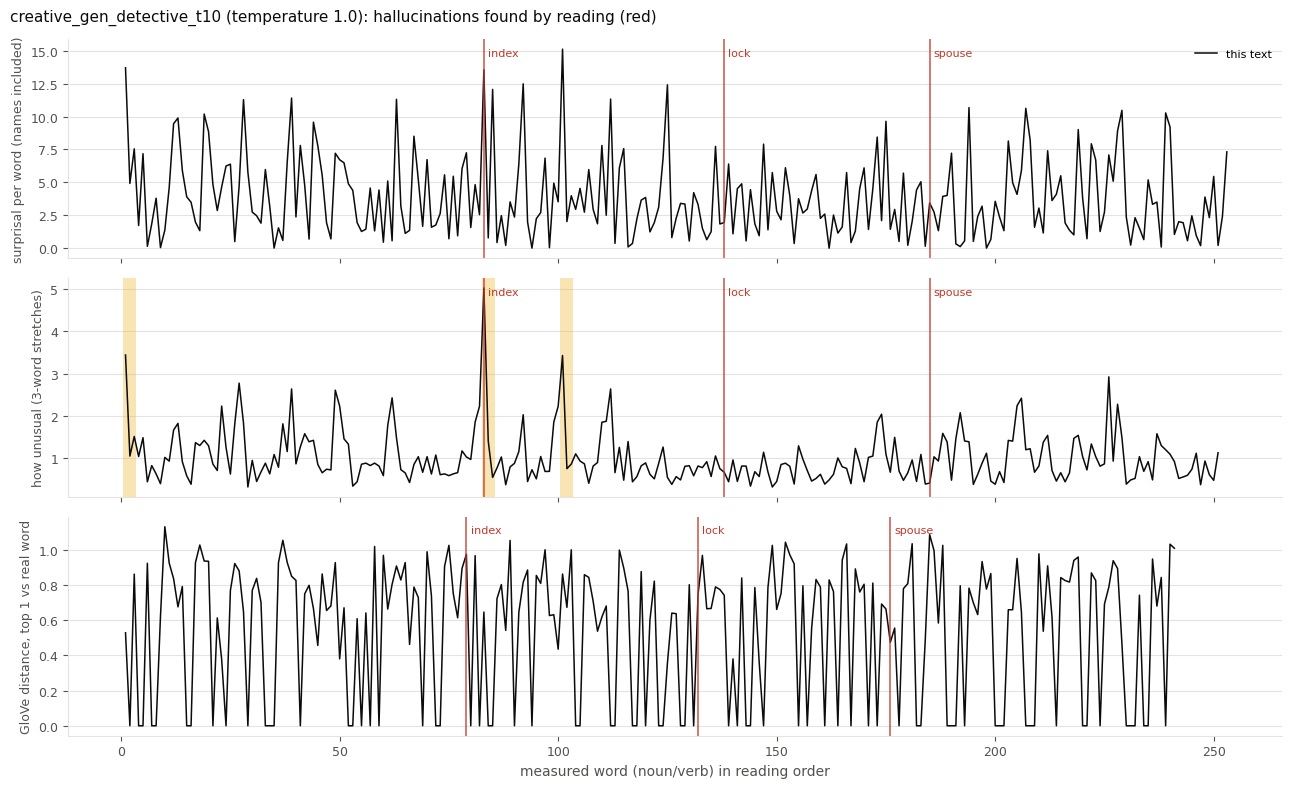

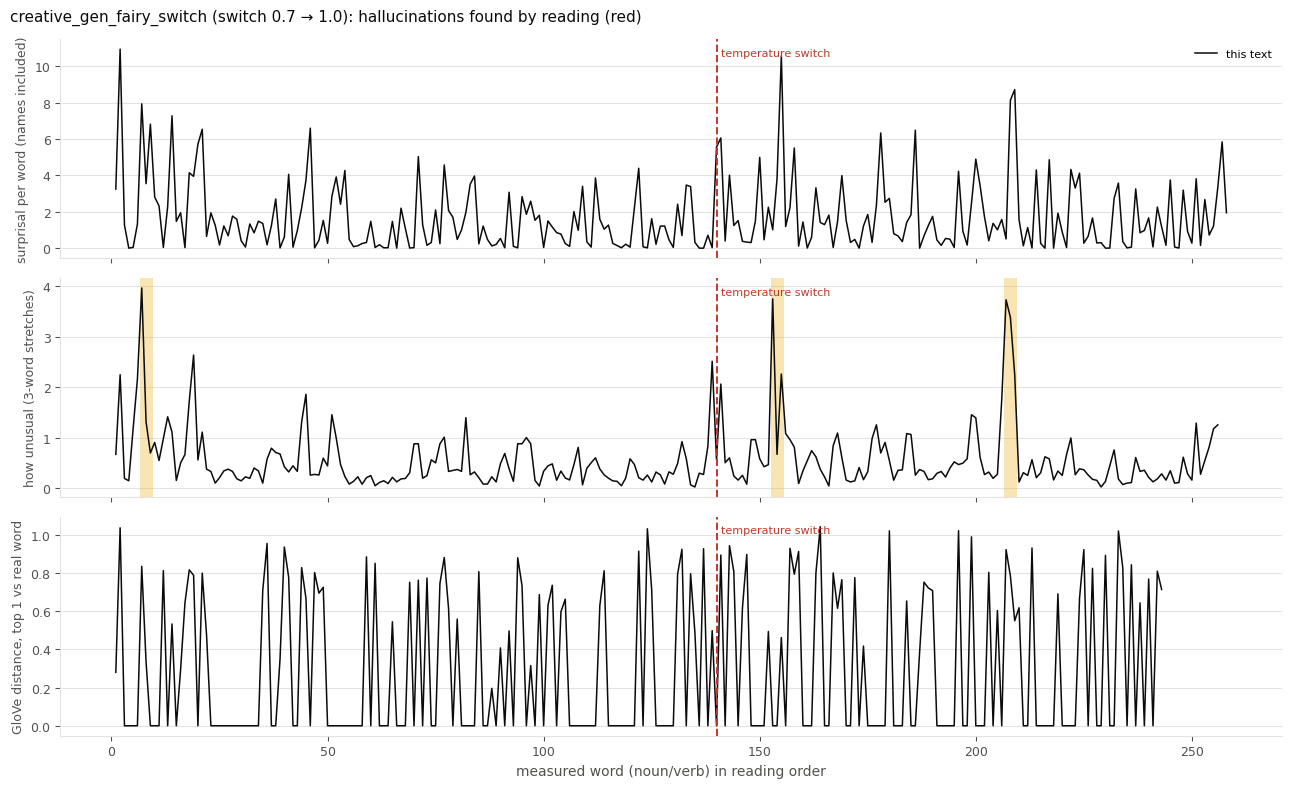

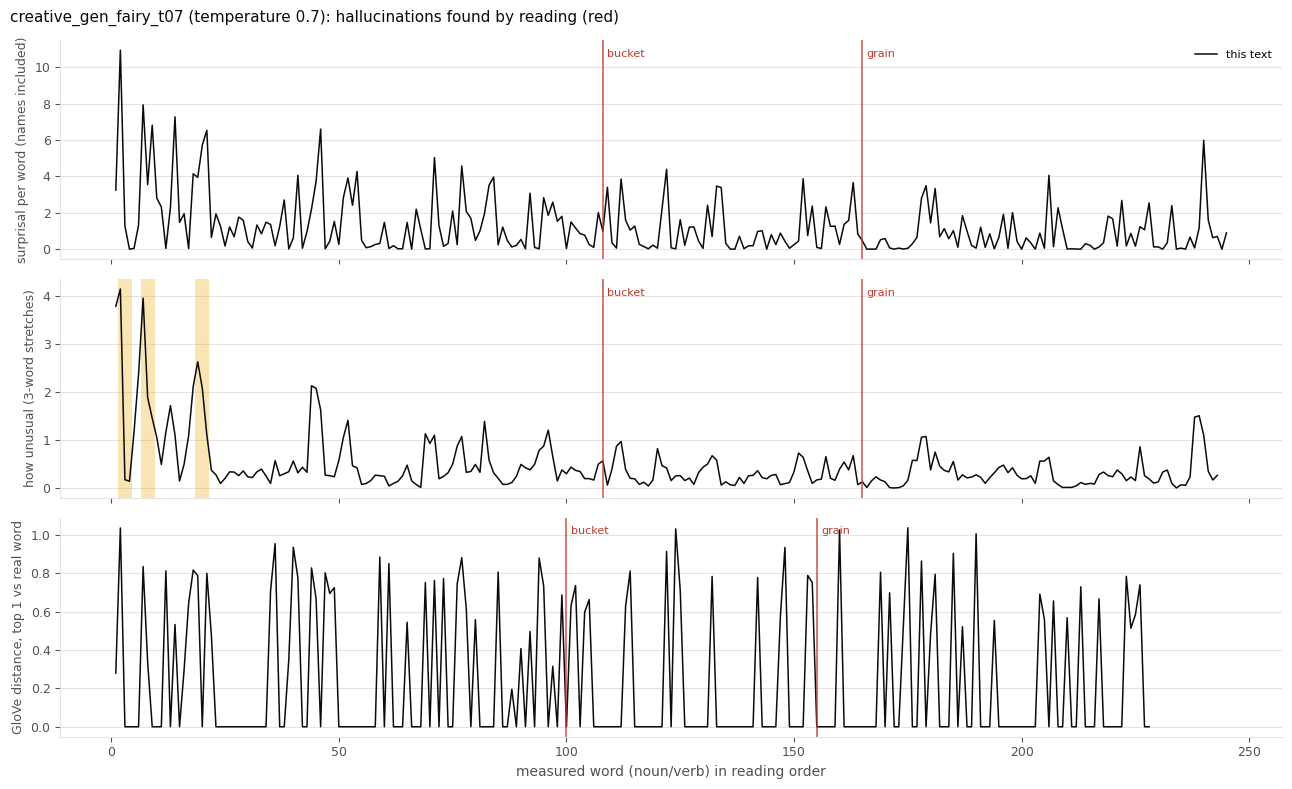

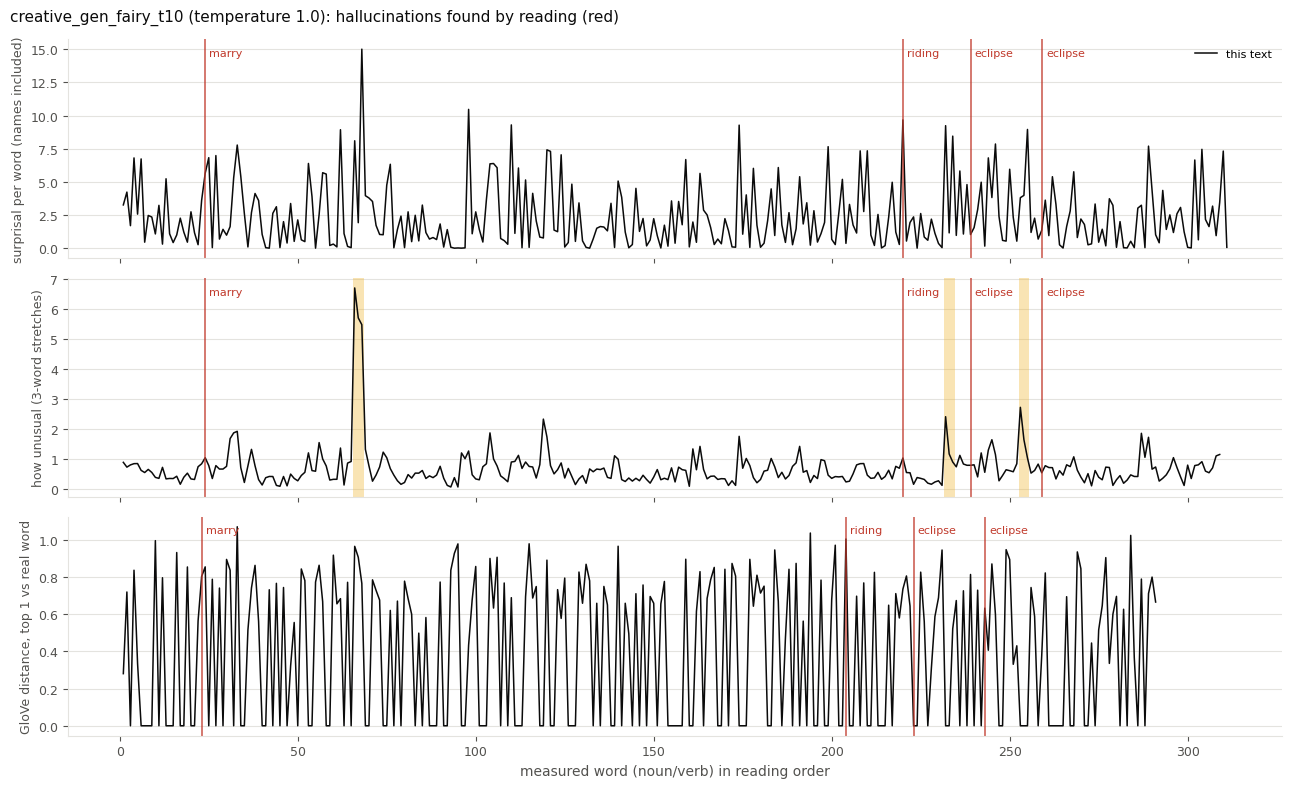

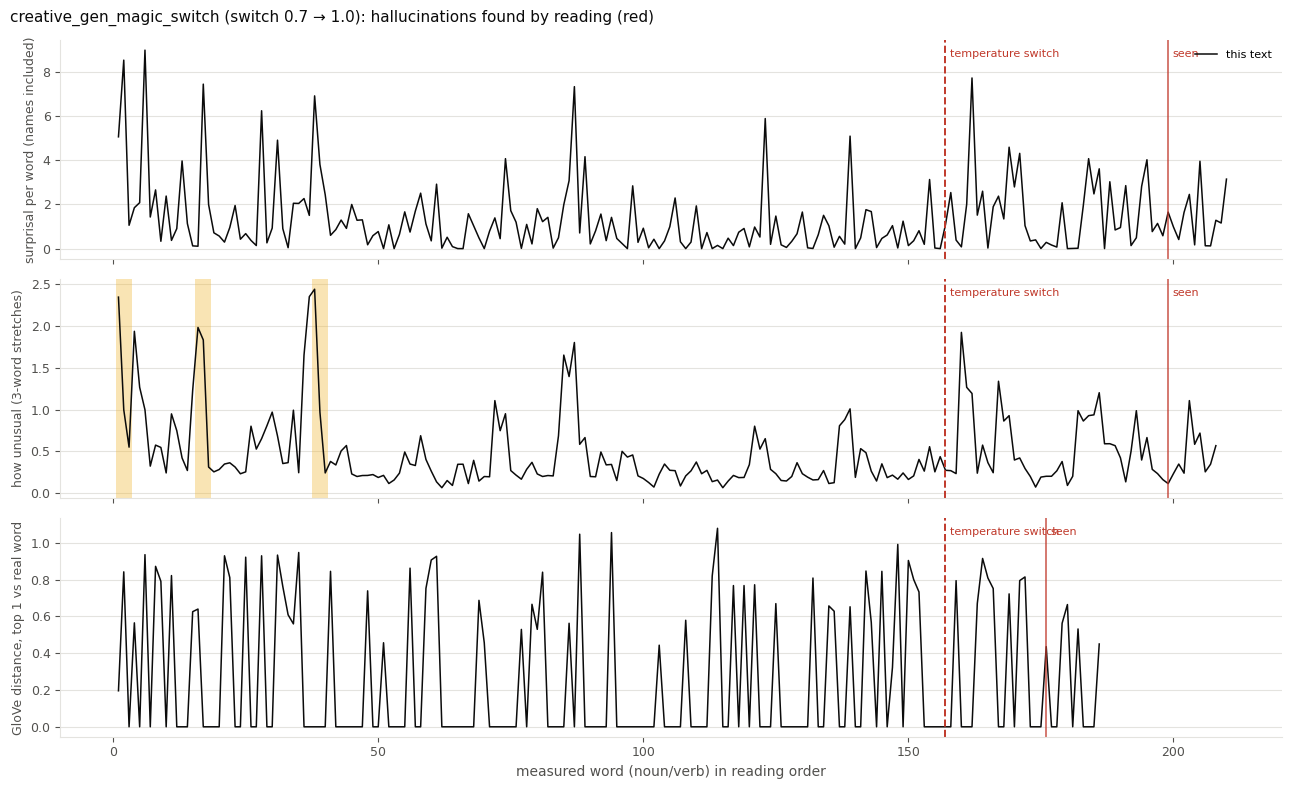

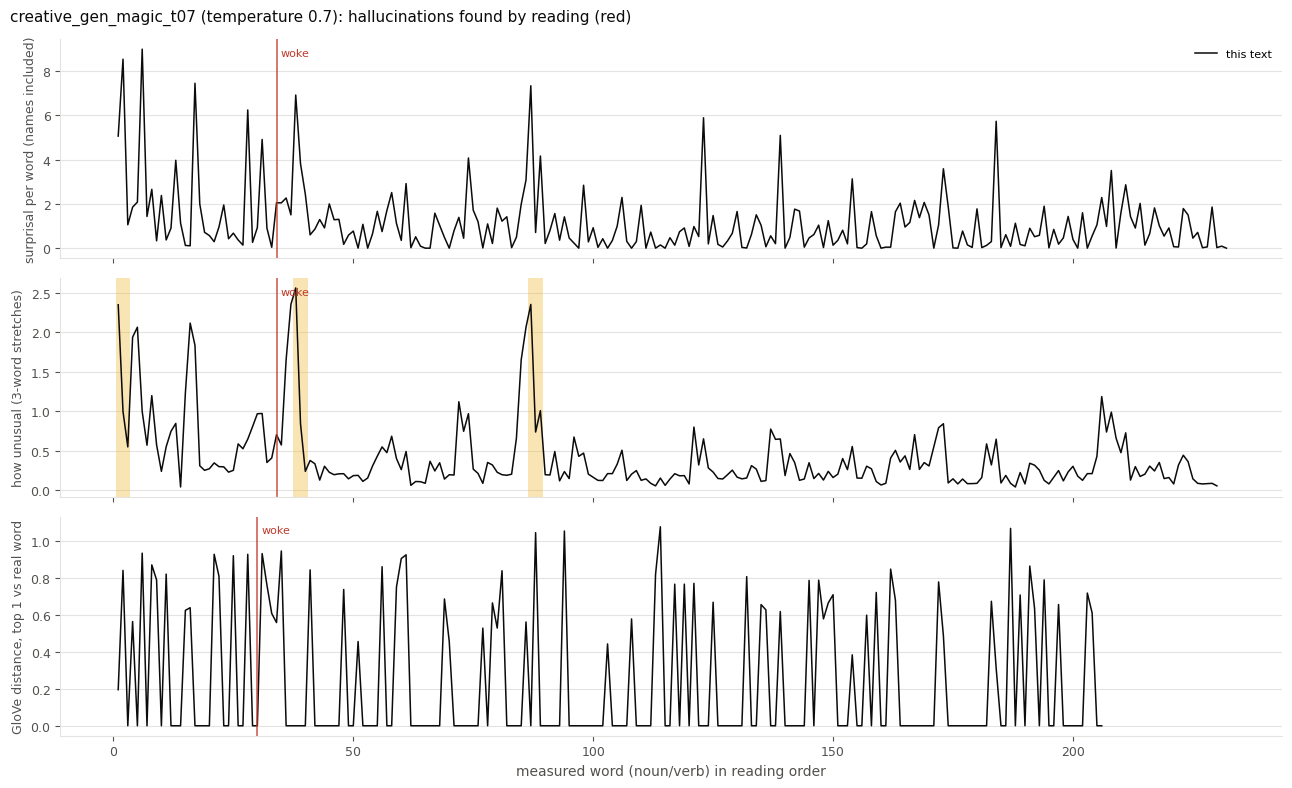

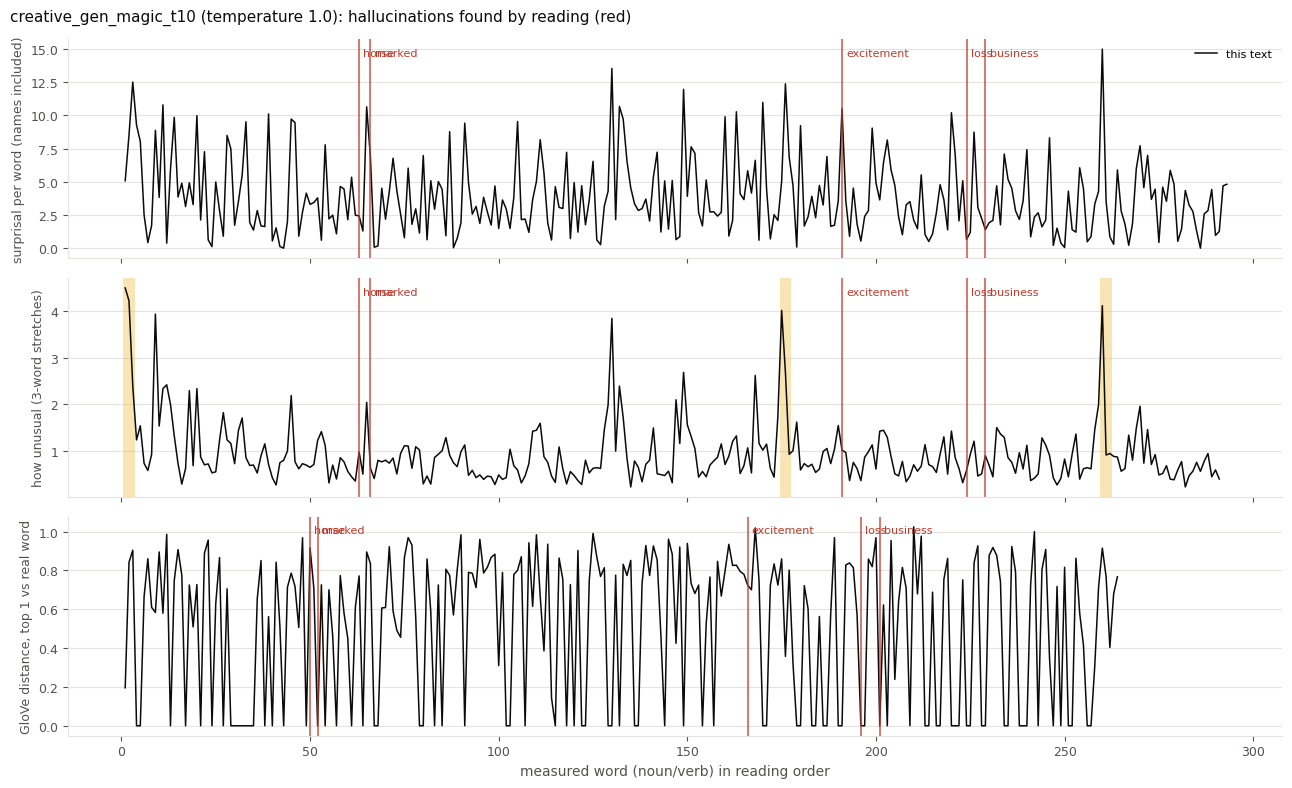

,text,word,signal,value,rank in text,in top 3 unusual stretches,stretch rank
0,creative_gen_detective_switch,enter,surprisal per word (names included),2.528,76 of 313,False,47.0
1,creative_gen_detective_switch,stayed,surprisal per word (names included),0.660,187 of 313,False,62.0
2,creative_gen_detective_switch,found,surprisal per word (names included),3.842,43 of 313,False,10.0
3,creative_gen_detective_switch,enter,"GloVe distance, top 1 vs real word",-0.000,237 of 263,NaN,NaN
4,creative_gen_detective_switch,stayed,"GloVe distance, top 1 vs real word",0.000,192 of 263,NaN,NaN
5,creative_gen_detective_switch,found,"GloVe distance, top 1 vs real word",0.435,112 of 263,NaN,NaN
6,creative_gen_detective_t07,reservation,surprisal per word (names included),5.932,7 of 317,False,35.0
7,creative_gen_detective_t07,clean,surprisal per word (names included),0.220,233 of 317,False,235.0
8,creative_gen_detective_t07,reservation,"GloVe distance, top 1 vs real word",0.776,46 of 256,NaN,NaN
9,creative_gen_detective_t07,clean,"GloVe distance, top 1 vs real word",0.000,169 of 256,NaN,NaN


In [5]:
mark_rows = []
for name in new_names:
    if "_gen_" not in name:
        continue
    text_marks = marks[marks["text"] == name]
    panels = []
    marks_by_signal = {}
    switch_position = None
    for signal_key in WORD_LEVEL_SIGNALS:
        signal_name, values, rows, table = word_curve(signal_key, name)
        panels.append({"signal": signal_name, "curve": values})
        profile = None
        if signal_key == "surprisal_per_word":
            panel, profile, stretches = profile_panel(signal_name, values)
            panels.append(panel)
            if name in set(switches["text"]):
                switch_char = int(switches.loc[switches["text"] == name, "switch char"].iloc[0])
                switch_position = curve_position(rows, first_row_from_char(table, switch_char))
        marks_by_signal[signal_name] = []
        for _index, mark in text_marks.iterrows():
            position = curve_position(rows, row_at_char(table, int(mark["char"])))
            row = {"text": name, "word": mark["word"], "signal": signal_name}
            if position is None:
                row["rank in text"] = "not on the curve"
            else:
                marks_by_signal[signal_name].append((position, mark["word"]))
                row["value"] = round(float(values[position]), 3)
                row["rank in text"] = f"{rank_in_curve(values, position)} of {len(values)}"
                if profile is not None:
                    marks_by_signal.setdefault(panel["signal"], []).append((position, mark["word"]))
                    row["in top 3 unusual stretches"] = in_top_anomalies(position, stretches, ANOMALY_WINDOW)
                    row["stretch rank"] = stretch_rank(profile, position, ANOMALY_WINDOW)
            mark_rows.append(row)
    figure = plot_word_curves(f"{name} ({group_of(name)}): hallucinations found by reading (red)", panels,
                              marks_by_signal, switch_position)
    save_to(figure, HALLUCINATED_FIGURES_DIR, f"generated_{name}.png")
    plt.show()

marked = pd.DataFrame(mark_rows)
marked.to_csv(HALLUCINATED_TABLES_DIR / "generated_marks.csv", index=False)
marked

## 5. A second reader: does another model see the same?
The same texts read by another model family (`SECOND_READER_MODEL`, OLMo-2 7B Instruct; notebook 03, section 5).
For every planted hallucination and every hallucination found in the generated stories: its rank in the text's own
surprisal curve (names included; 1 = highest) and whether it falls in one of the 3 most unusual stretches, for
Qwen and for the second reader. Qwen wrote the generated stories, so they are where a reader that did *not* write
them could differ most. The figure puts each hallucination at (Qwen rank, second-reader rank): points under the
diagonal were ranked higher (more surprising) by the second reader.

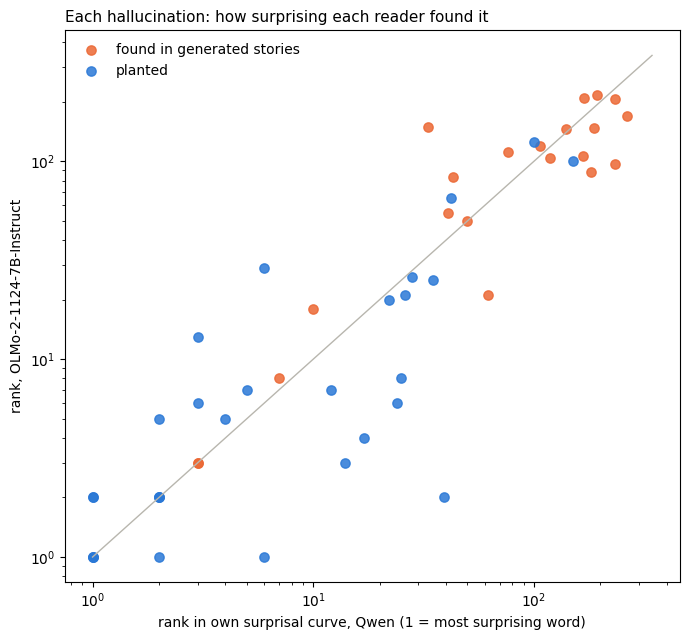

,hallucinations,reader,count,rank 1-3,rank 1-10,in top 3 stretch
0,planted,Qwen,29,12,16,10
1,planted,OLMo-2-1124-7B-Instruct,29,12,20,11
2,found in generated stories,Qwen,21,2,4,1
3,found in generated stories,OLMo-2-1124-7B-Instruct,21,2,3,1


In [6]:
import numpy as np

second_reader = SECOND_READER_MODEL.split("/")[-1]
second_named = {}
for path in sorted(SECOND_READER_TOKENS_DIR.glob("*.csv")):
    second_named[path.stem] = words_with_names(texts[path.stem], pd.read_csv(path))


def surprisal_look(table, char):
    # (rank in own curve, in top 3 unusual stretches, words on curve) of the word starting at char; None if not on it
    values, rows = curve_with_rows(table, "surprisal")
    position = curve_position(rows, row_at_char(table, char))
    if position is None:
        return None
    profile = anomaly_profile(values, ANOMALY_WINDOW)
    stretches = top_anomalies(profile, ANOMALY_WINDOW, ANOMALIES_SHOWN)
    return rank_in_curve(values, position), in_top_anomalies(position, stretches, ANOMALY_WINDOW), len(values)


hallucinations = []                       # (text, word, how it was made, char)
for name, (_original, _text, edits) in planted.items():
    for edit in edits:
        hallucinations.append((name, edit["planted"], "planted", edit["char"]))
for _index, mark in marks.iterrows():
    hallucinations.append((mark["text"], mark["word"], "found in " + group_of(mark["text"]), int(mark["char"])))

compare_rows = []
for name, word, made, char in hallucinations:
    if name not in second_named:
        continue
    qwen = surprisal_look(named_words[name], char)
    second = surprisal_look(second_named[name], char)
    if qwen is None or second is None:
        continue
    compare_rows.append({"text": name, "word": word, "made as": made,
                         "Qwen rank": qwen[0], f"{second_reader} rank": second[0], "words on curve": qwen[2],
                         "Qwen: top 3 stretch": qwen[1], f"{second_reader}: top 3 stretch": second[1]})
compare = pd.DataFrame(compare_rows)
compare.to_csv(HALLUCINATED_TABLES_DIR / "second_reader.csv", index=False)

summary_rows = []
for planted_or_found, rows in [("planted", compare[compare["made as"] == "planted"]),
                               ("found in generated stories", compare[compare["made as"] != "planted"])]:
    for reader in ["Qwen", second_reader]:
        summary_rows.append({"hallucinations": planted_or_found, "reader": reader, "count": len(rows),
                             "rank 1-3": int((rows[f"{reader} rank"] <= 3).sum()),
                             "rank 1-10": int((rows[f"{reader} rank"] <= 10).sum()),
                             "in top 3 stretch": int(rows[f"{reader}: top 3 stretch"].sum())})
summary = pd.DataFrame(summary_rows)
summary.to_csv(HALLUCINATED_TABLES_DIR / "second_reader_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6.5))
for made, rows in compare.groupby(compare["made as"] == "planted"):
    label = "planted" if made else "found in generated stories"
    colour = "#2a78d6" if made else "#eb6834"
    ax.scatter(rows["Qwen rank"], rows[f"{second_reader} rank"], s=45, color=colour, label=label, alpha=0.85)
top = max(compare["Qwen rank"].max(), compare[f"{second_reader} rank"].max()) * 1.3
ax.plot([1, top], [1, top], color="#b8b6ae", lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("rank in own surprisal curve, Qwen (1 = most surprising word)")
ax.set_ylabel(f"rank, {second_reader}")
ax.legend(frameon=False)
ax.set_title("Each hallucination: how surprising each reader found it", loc="left", fontsize=11)
fig.tight_layout()
save_to(fig, HALLUCINATED_FIGURES_DIR, "second_reader_ranks.png")
plt.show()
summary